# RQ4a — Equalized-Odds post-processing results

This notebook is a presentation-only consumer of the two accepted RQ4a production runs:

| Configuration | Role | Run ID |
|---|---|---|
| RQ4a-3 | Primary analysis on the fixed G3 roster | `rq4a3_postproc_20261017_01` |
| RQ4a-6 | Required sensitivity on the fixed G6 roster | `rq4a6_postproc_20261017_01` |

It reads only the `reporting/` directory of each run. It does not import Fairlearn, read raw data, model predictions, decision files or bootstrap indices, fit or apply any policy, or recompute metrics or confidence intervals. Every number shown is taken from the stored reporting artifacts; tables only round values for display.

All results use the project orientation `Approved = 1`. They describe how the frozen XGBoost and RealMLP decision rules change under post-processing for the documented HMDA approval cohort. They are not evidence of legal discrimination, causal effects, creditworthiness, or default risk.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "config/dataset_b/rq4a_postprocessing.yaml").exists())
RUNS = {"RQ4a-3": "rq4a3_postproc_20261017_01", "RQ4a-6": "rq4a6_postproc_20261017_01"}
REPORTING = {configuration: project_root / "artifacts/dataset_b/rq4/rq4a" / run_id / "reporting" for configuration, run_id in RUNS.items()}
MODELS = ["xgboost", "realmlp"]
MODEL_LABELS = {"xgboost": "XGBoost", "realmlp": "RealMLP"}
TARGET_EOD = {"RQ4a-3": "eod3", "RQ4a-6": "eod6"}
AUDIT_EOD = {"RQ4a-3": "eod6", "RQ4a-6": "eod3"}
PRIMARY_BA_BUDGET = 0.01  # locked contract constant, shown for reference only


def read_csv(configuration, name):
    return pd.read_csv(REPORTING[configuration] / name, float_precision="round_trip")


def read_json(configuration, name):
    return json.loads((REPORTING[configuration] / name).read_text(encoding="utf-8"))


print("Notebook kernel:", sys.executable, "| Python", platform.python_version(), "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
for configuration, path in REPORTING.items():
    print(configuration, "->", path.relative_to(project_root).as_posix())

Notebook kernel: C:\Users\Dan\anaconda3\python.exe | Python 3.13.9 | pandas 2.3.3 | matplotlib 3.10.6
RQ4a-3 -> artifacts/dataset_b/rq4/rq4a/rq4a3_postproc_20261017_01/reporting
RQ4a-6 -> artifacts/dataset_b/rq4/rq4a/rq4a6_postproc_20261017_01/reporting


## Reporting integrity and producer provenance

Each reporting file is hashed and compared with the SHA-256 recorded in the run's own `artifact_index.json`. The producer provenance is the interpreter and package set that generated the run.

In [2]:
index = {configuration: read_json(configuration, "artifact_index.json") for configuration in RUNS}
integrity_rows = []
for configuration in RUNS:
    entries = {entry["relative_path"]: entry for entry in index[configuration]["files"]}
    for path in sorted(REPORTING[configuration].iterdir()):
        relative = f"reporting/{path.name}"
        if relative == "reporting/artifact_index.json":
            continue
        integrity_rows.append(
            {
                "configuration": configuration,
                "file": relative,
                "sha256_matches_index": hashlib.sha256(path.read_bytes()).hexdigest() == entries[relative]["sha256"],
                "bytes": entries[relative]["bytes"],
                "rows": entries[relative]["rows"],
            }
        )
integrity = pd.DataFrame(integrity_rows)
display(integrity)
assert integrity["sha256_matches_index"].all(), "A reporting file differs from its artifact index."

provenance = pd.DataFrame(
    {
        configuration: {"sys_executable": index[configuration]["runtime_provenance"]["sys_executable"], "python": index[configuration]["runtime_provenance"]["python_version"], **index[configuration]["runtime_provenance"]["packages"]}
        for configuration in RUNS
    }
)
display(provenance)

,configuration,file,sha256_matches_index,bytes,rows
0,RQ4a-3,reporting/bootstrap_summary.csv,True,1104,6.0
1,RQ4a-3,reporting/decision_changes.csv,True,1900,20.0
2,RQ4a-3,reporting/experiment_metrics.csv,True,3264,8.0
3,RQ4a-3,reporting/group_metrics.csv,True,21947,112.0
4,RQ4a-3,reporting/model_summary.json,True,3784,NaN
5,RQ4a-3,reporting/randomization_sensitivity.csv,True,10687,60.0
6,RQ4a-3,reporting/runtime.csv,True,1549,10.0
7,RQ4a-6,reporting/bootstrap_summary.csv,True,1133,6.0
8,RQ4a-6,reporting/decision_changes.csv,True,1999,20.0
9,RQ4a-6,reporting/experiment_metrics.csv,True,3267,8.0


,RQ4a-3,RQ4a-6
sys_executable,D:\Proj\DAP\DAP391m_GR12\.venv-rq4a-cpu\Script...,D:\Proj\DAP\DAP391m_GR12\.venv-rq4a-cpu\Script...
python,3.13.14,3.13.14
numpy,2.5.2,2.5.2
pandas,3.0.5,3.0.5
scipy,1.18.1,1.18.1
scikit_learn,1.9.1,1.9.1
pyyaml,6.0.3,6.0.3
joblib,1.6.0,1.6.0
fairlearn,0.15.0,0.15.0


## Run and model status

`execution_status`, `stability_status`, and `primary_criterion` are independent fields. A `fail` criterion or an `unstable` status is a study outcome, not an execution failure.

In [3]:
summary = {configuration: read_json(configuration, "model_summary.json") for configuration in RUNS}
status = pd.DataFrame(
    [
        {
            "configuration": configuration,
            "run_id": summary[configuration]["run_id"],
            "model": MODEL_LABELS[model],
            "target_eod": TARGET_EOD[configuration],
            "audit_eod": AUDIT_EOD[configuration],
            "execution_status": summary[configuration]["model_summaries"][model]["execution_status"],
            "stability_status": summary[configuration]["model_summaries"][model]["stability_status"],
            "primary_criterion": summary[configuration]["model_summaries"][model]["primary_criterion"],
            "reason_codes": ", ".join(summary[configuration]["model_summaries"][model]["reason_codes"]),
        }
        for configuration in RUNS
        for model in MODELS
    ]
)
display(status)

,configuration,run_id,model,target_eod,audit_eod,execution_status,stability_status,primary_criterion,reason_codes
0,RQ4a-3,rq4a3_postproc_20261017_01,XGBoost,eod3,eod6,completed,stable,pass,none
1,RQ4a-3,rq4a3_postproc_20261017_01,RealMLP,eod3,eod6,completed,stable,pass,none
2,RQ4a-6,rq4a6_postproc_20261017_01,XGBoost,eod6,eod3,completed,unstable,fail,"target_eod_reduction_not_demonstrated, ba_budg..."
3,RQ4a-6,rq4a6_postproc_20261017_01,RealMLP,eod6,eod3,completed,unstable,fail,"target_eod_reduction_not_demonstrated, ba_budg..."


## Frozen baseline, RQ4a-3, and RQ4a-6

The frozen baseline rows are identical in both runs (checked below), so they are shown once. Balanced Accuracy uses the full partition, including rows outside the mitigated roster. ROC-AUC and Brier are inherited from the frozen scores and are not post-processing gains.

### Test partition

balanced_accuracy    eod3  eod3_valid    eod6  eod6_valid  denied_f1  denied_precision  denied_recall  sex_eod  sex_eod_valid  roc_auc_inherited  brier_inherited
model   setting                                                                                                                                                                            
RealMLP Frozen baseline              0.7828  0.0925        True  0.2072        True     0.6743            0.6678         0.6810   0.0340           True             0.8632           0.1065
        RQ4a-3 mitigated             0.7798  0.0331        True  0.2072        True     0.6680            0.6538         0.6829   0.0306           True             0.8632           0.1065
        RQ4a-6 mitigated             0.7777  0.0262        True  0.1416        True     0.6574            0.6155         0.7055   0.0271           True             0.8632           0.1065
XGBoost Frozen baseline              0.7830  0.1150        True  0.1672        True     0.6634            0.6164         0.7183   0.0201           True             0.8641           0.1314
        RQ4a-3 mitigated             0.7816  0.0412        True  0.1672        True     0.6644            0.6272         0.7063   0.0206           True             0.8641           0.1314
        RQ4a-6 mitigated             0.7799  0.0532        True  0.0805        True     0.6617            0.6235         0.7049   0.0176           True             0.8641           0.1314

### Validation partition (complete-Validation development evaluation)

balanced_accuracy    eod3  eod3_valid    eod6  eod6_valid  denied_f1  denied_precision  denied_recall  sex_eod  sex_eod_valid  roc_auc_inherited  brier_inherited
model   setting                                                                                                                                                                            
RealMLP Frozen baseline              0.7866  0.0742        True  0.2352        True     0.6808            0.6777         0.6839   0.0277           True             0.8645           0.1058
        RQ4a-3 mitigated             0.7843  0.0131        True  0.2352        True     0.6753            0.6638         0.6872   0.0251           True             0.8645           0.1058
        RQ4a-6 mitigated             0.7807  0.0109        True  0.0610        True     0.6629            0.6249         0.7058   0.0251           True             0.8645           0.1058
XGBoost Frozen baseline              0.7869  0.1001        True  0.2141        True     0.6693            0.6237         0.7222   0.0303           True             0.8651           0.1308
        RQ4a-3 mitigated             0.7846  0.0109        True  0.1994        True     0.6686            0.6314         0.7106   0.0257           True             0.8651           0.1308
        RQ4a-6 mitigated             0.7825  0.0046        True  0.0719        True     0.6657            0.6287         0.7074   0.0258           True             0.8651           0.1308

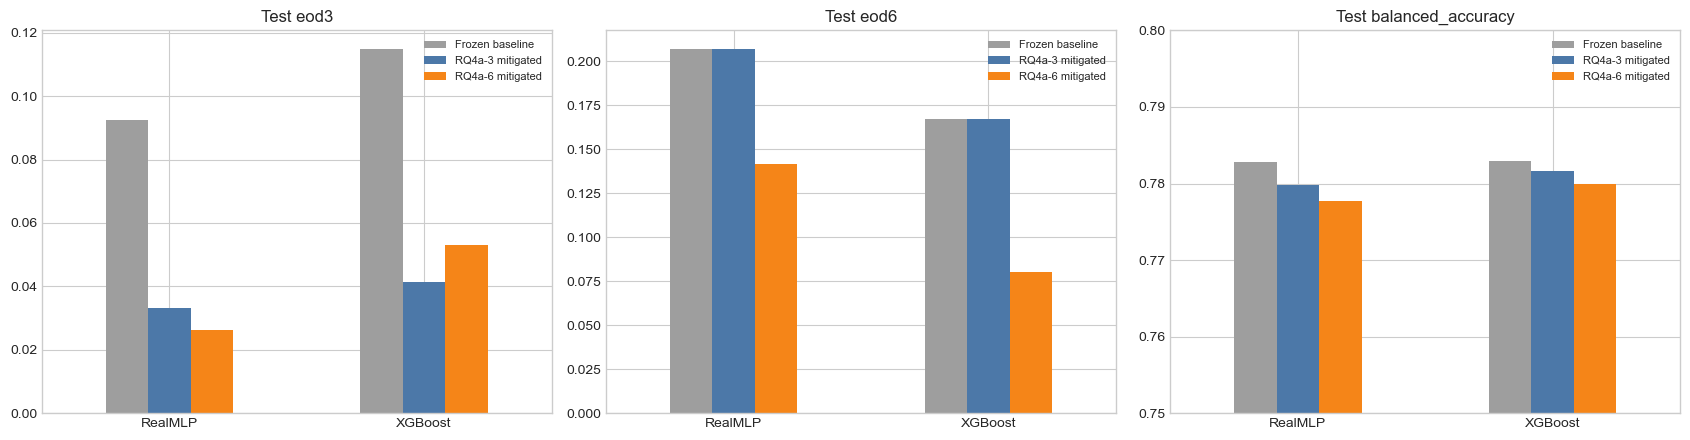

In [4]:
experiment = pd.concat([read_csv(configuration, "experiment_metrics.csv") for configuration in RUNS], ignore_index=True)
baseline_3 = experiment[(experiment["configuration_id"] == "RQ4a-3") & (experiment["policy"] == "baseline")].drop(columns=["run_id", "configuration_id"]).reset_index(drop=True)
baseline_6 = experiment[(experiment["configuration_id"] == "RQ4a-6") & (experiment["policy"] == "baseline")].drop(columns=["run_id", "configuration_id"]).reset_index(drop=True)
assert baseline_3.equals(baseline_6), "Frozen-baseline rows differ between the two runs."

METRIC_COLUMNS = ["balanced_accuracy", "eod3", "eod3_valid", "eod6", "eod6_valid", "denied_f1", "denied_precision", "denied_recall", "sex_eod", "sex_eod_valid", "roc_auc_inherited", "brier_inherited"]


def comparison(partition):
    base = experiment[(experiment["configuration_id"] == "RQ4a-3") & (experiment["partition"] == partition) & (experiment["policy"] == "baseline")].assign(setting="Frozen baseline")
    mitigated = experiment[(experiment["partition"] == partition) & (experiment["policy"] == "mitigated")]
    mitigated = mitigated.assign(setting=mitigated["configuration_id"] + " mitigated")
    table = pd.concat([base, mitigated], ignore_index=True)
    table["model"] = table["model"].map(MODEL_LABELS)
    order = {"Frozen baseline": 0, "RQ4a-3 mitigated": 1, "RQ4a-6 mitigated": 2}
    return table.sort_values(["model", "setting"], key=lambda s: s.map(order) if s.name == "setting" else s).set_index(["model", "setting"])[METRIC_COLUMNS]


display(Markdown("### Test partition"))
test_comparison = comparison("test")
display(test_comparison.round(4))
display(Markdown("### Validation partition (complete-Validation development evaluation)"))
display(comparison("validation").round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ["eod3", "eod6", "balanced_accuracy"]):
    test_comparison[metric].unstack("setting")[["Frozen baseline", "RQ4a-3 mitigated", "RQ4a-6 mitigated"]].plot.bar(ax=ax, rot=0, color=["#9E9E9E", "#4C78A8", "#F58518"])
    ax.set_title(f"Test {metric}")
    ax.set_xlabel("")
    ax.legend(fontsize=8)
axes[2].set_ylim(0.75, 0.80)
plt.tight_layout()
plt.show()

## Paired bootstrap deltas and confidence intervals

`delta_eod = mitigated_eod - baseline_eod` and `ba_cost = baseline_ba - mitigated_ba` are evaluated on the same locked Test rows in each replicate. Intervals are two-sided 95% percentile intervals over the valid replicates of each quantity, as stored in `bootstrap_summary.csv`. The target EOD is EOD3 for RQ4a-3 and EOD6 for RQ4a-6; the other EOD is an audit metric that never gates the criterion.

,configuration_id,model_label,quantity,label,point_estimate,ci_lower,ci_upper,confidence_level,ci_method,quantile_method,n_replicates,n_valid,minimum_valid,valid_gate_status
0,RQ4a-3,XGBoost,delta_target_eod,delta EOD3 (target),-0.07377,-0.10750,-0.02455,0.95,percentile,linear,1000,1000,950,pass
1,RQ4a-3,XGBoost,ba_cost,BA cost,0.00135,0.00013,0.00629,0.95,percentile,linear,1000,1000,950,pass
2,RQ4a-3,XGBoost,delta_audit_eod,delta EOD6 (audit),0.00000,-0.04178,0.04356,0.95,percentile,linear,1000,1000,950,pass
3,RQ4a-3,RealMLP,delta_target_eod,delta EOD3 (target),-0.05943,-0.08392,-0.00791,0.95,percentile,linear,1000,1000,950,pass
4,RQ4a-3,RealMLP,ba_cost,BA cost,0.00295,0.00097,0.00681,0.95,percentile,linear,1000,1000,950,pass
5,RQ4a-3,RealMLP,delta_audit_eod,delta EOD6 (audit),0.00000,-0.01907,0.00857,0.95,percentile,linear,1000,1000,950,pass
6,RQ4a-6,XGBoost,delta_target_eod,delta EOD6 (target),-0.08671,-0.15738,0.09154,0.95,percentile,linear,1000,1000,950,pass
7,RQ4a-6,XGBoost,ba_cost,BA cost,0.00307,0.00108,0.01388,0.95,percentile,linear,1000,1000,950,pass
8,RQ4a-6,XGBoost,delta_audit_eod,delta EOD3 (audit),-0.06184,-0.10700,-0.02484,0.95,percentile,linear,1000,1000,950,pass
9,RQ4a-6,RealMLP,delta_target_eod,delta EOD6 (target),-0.06558,-0.22131,0.14461,0.95,percentile,linear,1000,1000,950,pass


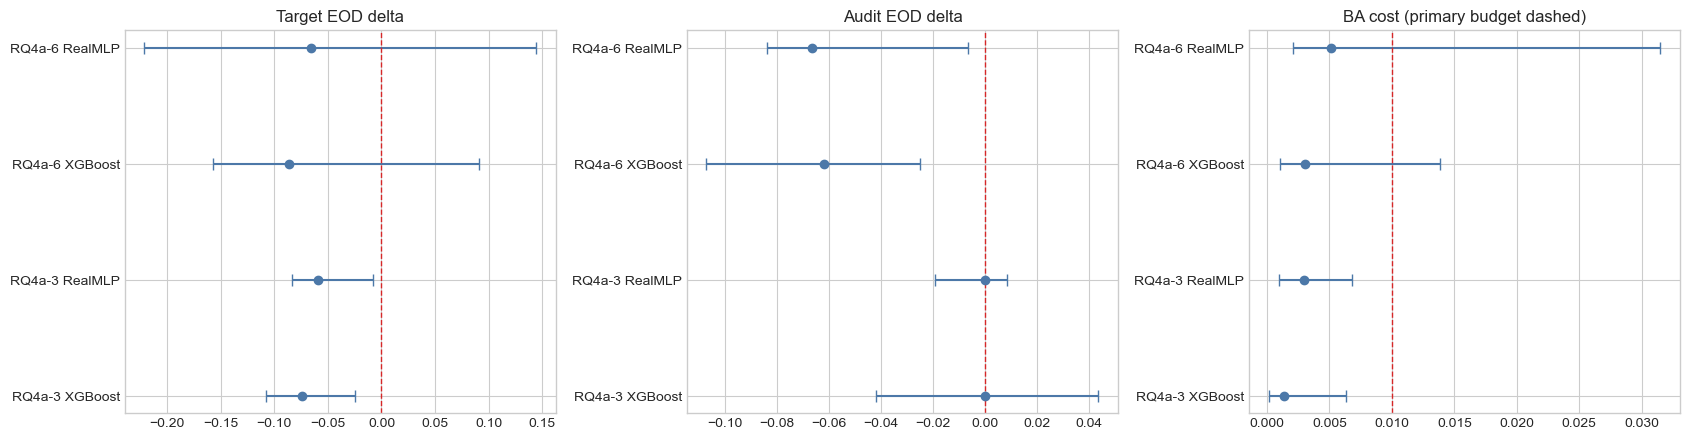

In [5]:
bootstrap = pd.concat([read_csv(configuration, "bootstrap_summary.csv") for configuration in RUNS], ignore_index=True)
QUANTITY_LABEL = {
    ("RQ4a-3", "delta_target_eod"): "delta EOD3 (target)",
    ("RQ4a-3", "delta_audit_eod"): "delta EOD6 (audit)",
    ("RQ4a-6", "delta_target_eod"): "delta EOD6 (target)",
    ("RQ4a-6", "delta_audit_eod"): "delta EOD3 (audit)",
}
bootstrap["label"] = [QUANTITY_LABEL.get((c, q), "BA cost") for c, q in zip(bootstrap["configuration_id"], bootstrap["quantity"])]
bootstrap["model_label"] = bootstrap["model"].map(MODEL_LABELS)
display(bootstrap[["configuration_id", "model_label", "quantity", "label", "point_estimate", "ci_lower", "ci_upper", "confidence_level", "ci_method", "quantile_method", "n_replicates", "n_valid", "minimum_valid", "valid_gate_status"]].round(5))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, quantity, reference, title in zip(
    axes,
    ["delta_target_eod", "delta_audit_eod", "ba_cost"],
    [0.0, 0.0, PRIMARY_BA_BUDGET],
    ["Target EOD delta", "Audit EOD delta", "BA cost (primary budget dashed)"],
):
    subset = bootstrap[bootstrap["quantity"] == quantity].reset_index(drop=True)
    labels = subset["configuration_id"] + " " + subset["model_label"]
    y = np.arange(len(subset))
    ax.errorbar(subset["point_estimate"], y, xerr=[subset["point_estimate"] - subset["ci_lower"], subset["ci_upper"] - subset["point_estimate"]], fmt="o", color="#4C78A8", capsize=4)
    ax.axvline(reference, color="#D62728", linestyle="--", linewidth=1)
    ax.set_yticks(y, labels)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## BA cost and utility budget

The primary BA budget is 0.01. The 0.005 and 0.02 budgets are reporting sensitivities only and never change `primary_criterion`. The booleans below are read from `model_summary.json`.

In [6]:
budget_rows = []
for configuration in RUNS:
    for model in MODELS:
        entry = summary[configuration]["model_summaries"][model]
        row = {
            "configuration": configuration,
            "model": MODEL_LABELS[model],
            "point_ba_cost": entry["point_ba_cost"],
            "ba_cost_ci_lower": entry["ba_cost_ci"][0],
            "ba_cost_ci_upper": entry["ba_cost_ci"][1],
            "n_valid_ba_cost": entry["n_valid_ba_cost"],
            "primary_criterion": entry["primary_criterion"],
            "reason_codes": ", ".join(entry["reason_codes"]),
        }
        for budget, flags in entry["ba_budget_sensitivity"].items():
            row[f"point_le_{budget}"] = flags["point_ba_cost_le_budget"]
            row[f"ci_upper_le_{budget}"] = flags["ba_cost_ci_upper_le_budget"]
        budget_rows.append(row)
display(pd.DataFrame(budget_rows).round(5))

,configuration,model,point_ba_cost,ba_cost_ci_lower,ba_cost_ci_upper,n_valid_ba_cost,primary_criterion,reason_codes,point_le_0.005,ci_upper_le_0.005,point_le_0.02,ci_upper_le_0.02
0,RQ4a-3,XGBoost,0.00135,0.00013,0.00629,1000,pass,none,True,False,True,True
1,RQ4a-3,RealMLP,0.00295,0.00097,0.00681,1000,pass,none,True,False,True,True
2,RQ4a-6,XGBoost,0.00307,0.00108,0.01388,1000,fail,"target_eod_reduction_not_demonstrated, ba_budg...",True,False,True,True
3,RQ4a-6,RealMLP,0.00512,0.00209,0.03149,1000,fail,"target_eod_reduction_not_demonstrated, ba_budg...",False,False,True,False


## Per-group TPR, FPR, and selection rate

Values are the stored Test-partition group metrics for `derived_race` (application-level applicant/co-applicant aggregation; `Joint` is not an applicant race). TPR uses actual Approved applications as its denominator and FPR uses actual Denied applications. Undefined values (below the 100-row or 30/30 denominator gates) stay empty.

G3 roster: ['White', 'Black or African American', 'Asian']
G6 roster: ['White', 'Black or African American', 'Asian', 'American Indian or Alaska Native', '2 or more minority races', 'Joint']


### RQ4a-3 — Test, G6 groups (target roster: White, Black or African American, Asian)

fpr                              selection_rate                                   tpr                             
model                             realmlp            xgboost                  realmlp            xgboost            realmlp            xgboost          
policy                           baseline mitigated baseline mitigated       baseline mitigated baseline mitigated baseline mitigated baseline mitigated
group                                                                                                                                                   
White                              0.3204    0.3174   0.2799    0.2976         0.7468    0.7446   0.7071    0.7271   0.8736    0.8716   0.8342    0.8548
Black or African American          0.3023    0.3346   0.2656    0.3125         0.6374    0.6513   0.5975    0.6398   0.8557    0.8576   0.8137    0.8528
Asian                              0.3493    0.3015   0.3160    0.2713         0.8033    0.7374   0.7804    0.7148   0.9482    0.8766   0.9287    0.8563
American Indian or Alaska Native   0.2078    0.2078   0.2338    0.2338         0.6138    0.6138   0.6032    0.6032   0.8929    0.8929   0.8571    0.8571
2 or more minority races           0.2203    0.2203   0.1525    0.1525         0.5536    0.5536   0.4911    0.4911   0.9245    0.9245   0.8679    0.8679
Joint                              0.4150    0.4150   0.3197    0.3197         0.8235    0.8235   0.7752    0.7752   0.9207    0.9207   0.8835    0.8835

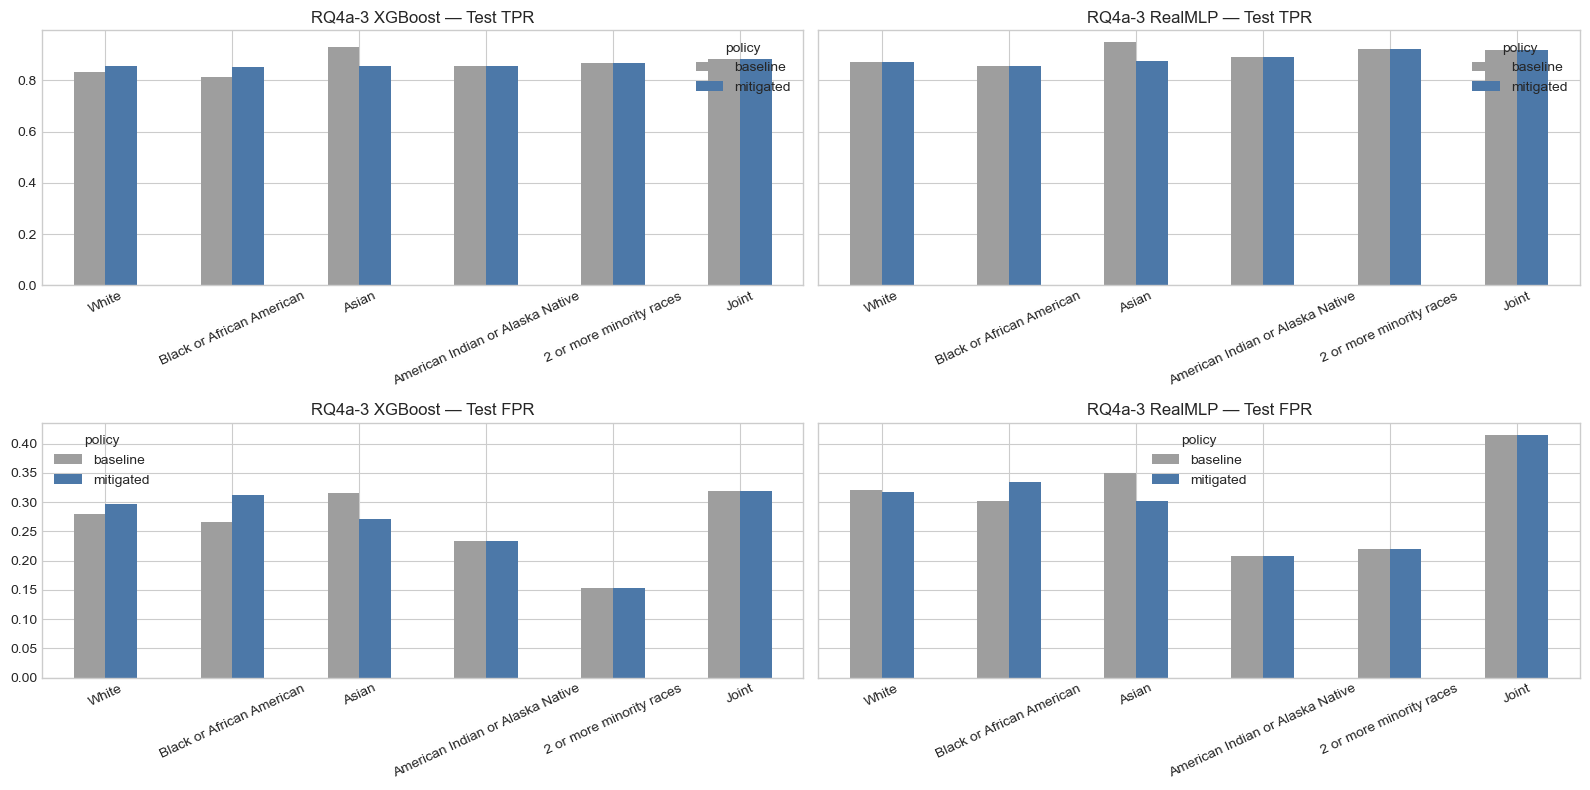

### RQ4a-6 — Test, G6 groups (target roster: White, Black or African American, Asian, American Indian or Alaska Native, 2 or more minority races, Joint)

fpr                              selection_rate                                   tpr                             
model                             realmlp            xgboost                  realmlp            xgboost            realmlp            xgboost          
policy                           baseline mitigated baseline mitigated       baseline mitigated baseline mitigated baseline mitigated baseline mitigated
group                                                                                                                                                   
White                              0.3204    0.2889   0.2799    0.2975         0.7468    0.7140   0.7071    0.7271   0.8736    0.8404   0.8342    0.8548
Black or African American          0.3023    0.3037   0.2656    0.3213         0.6374    0.6218   0.5975    0.6386   0.8557    0.8290   0.8137    0.8452
Asian                              0.3493    0.2775   0.3160    0.2682         0.8033    0.7075   0.7804    0.7082   0.9482    0.8447   0.9287    0.8487
American Indian or Alaska Native   0.2078    0.3636   0.2338    0.3117         0.6138    0.6455   0.6032    0.6455   0.8929    0.8393   0.8571    0.8750
2 or more minority races           0.2203    0.3729   0.1525    0.3390         0.5536    0.5893   0.4911    0.5893   0.9245    0.8302   0.8679    0.8679
Joint                              0.4150    0.2313   0.3197    0.2585         0.8235    0.7216   0.7752    0.7242   0.9207    0.8382   0.8835    0.8350

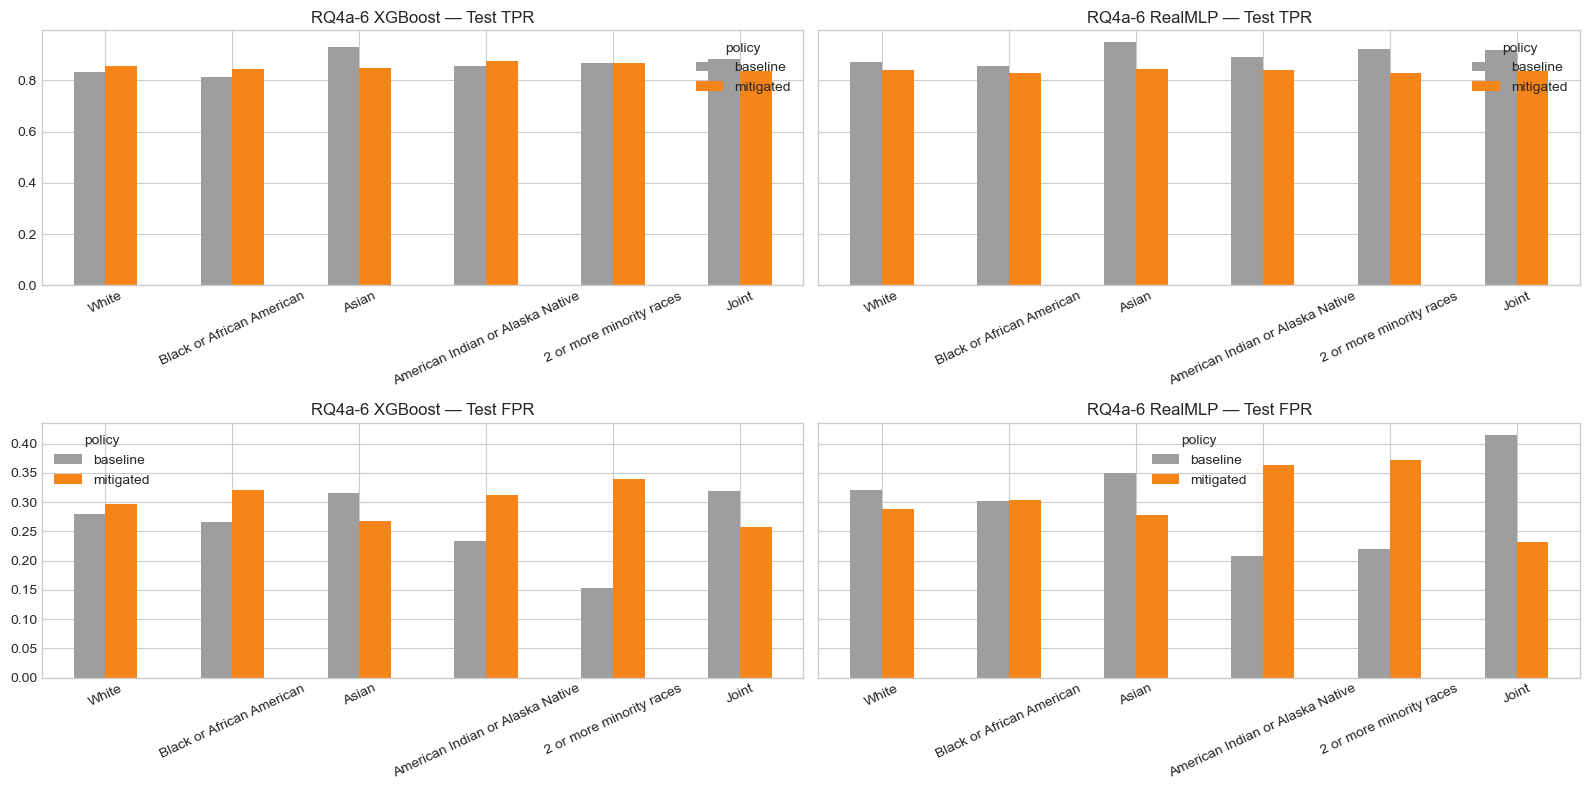

### Coverage-only groups outside G6 (frozen baseline decisions in both configurations)

,configuration_id,model,policy,group,n_rows,n_actual_approved,n_actual_denied,tpr,fpr,selection_rate
34,RQ4a-3,xgboost,baseline,Native Hawaiian or Other Pacific Islander,97,45,52,0.7333,0.1538,NaN
35,RQ4a-3,xgboost,baseline,Free Form Text Only,21,5,16,NaN,NaN,NaN
36,RQ4a-3,xgboost,baseline,Race Not Available,7589,5454,2135,0.8656,0.2890,0.7034
48,RQ4a-3,xgboost,mitigated,Native Hawaiian or Other Pacific Islander,97,45,52,0.7333,0.1538,NaN
49,RQ4a-3,xgboost,mitigated,Free Form Text Only,21,5,16,NaN,NaN,NaN
50,RQ4a-3,xgboost,mitigated,Race Not Available,7589,5454,2135,0.8656,0.2890,0.7034
90,RQ4a-3,realmlp,baseline,Native Hawaiian or Other Pacific Islander,97,45,52,0.8000,0.1538,NaN
91,RQ4a-3,realmlp,baseline,Free Form Text Only,21,5,16,NaN,NaN,NaN
92,RQ4a-3,realmlp,baseline,Race Not Available,7589,5454,2135,0.8999,0.3171,0.7359
104,RQ4a-3,realmlp,mitigated,Native Hawaiian or Other Pacific Islander,97,45,52,0.8000,0.1538,NaN


### Applicant-sex safety audit groups (Test)

,configuration_id,model,policy,group,n_rows,tpr,fpr,selection_rate,tpr_valid,fpr_valid
37,RQ4a-3,xgboost,baseline,Male,24799,0.8486,0.2899,0.7091,True,True
38,RQ4a-3,xgboost,baseline,Female,15347,0.8434,0.2698,0.6942,True,True
39,RQ4a-3,xgboost,baseline,Information not provided,2384,0.8291,0.2839,0.6640,True,True
40,RQ4a-3,xgboost,baseline,Not applicable,1439,0.8997,0.2662,0.7839,True,True
41,RQ4a-3,xgboost,baseline,Applicant selected both male and female,27,NaN,NaN,NaN,False,False
51,RQ4a-3,xgboost,mitigated,Male,24799,0.8592,0.3031,0.7204,True,True
52,RQ4a-3,xgboost,mitigated,Female,15347,0.8528,0.2826,0.7045,True,True
53,RQ4a-3,xgboost,mitigated,Information not provided,2384,0.8291,0.2853,0.6644,True,True
54,RQ4a-3,xgboost,mitigated,Not applicable,1439,0.8997,0.2662,0.7839,True,True
55,RQ4a-3,xgboost,mitigated,Applicant selected both male and female,27,NaN,NaN,NaN,False,False


In [7]:
groups = pd.concat([read_csv(configuration, "group_metrics.csv") for configuration in RUNS], ignore_index=True)
race = groups[groups["attribute"] == "derived_race"].copy()
G3 = race[(race["configuration_id"] == "RQ4a-3") & race["in_target_roster"]]["group"].drop_duplicates().tolist()
G6 = race[(race["configuration_id"] == "RQ4a-6") & race["in_target_roster"]]["group"].drop_duplicates().tolist()
print("G3 roster:", G3)
print("G6 roster:", G6)

test_race = race[race["partition"] == "test"]
for configuration in RUNS:
    roster = G3 if configuration == "RQ4a-3" else G6
    table = test_race[(test_race["configuration_id"] == configuration) & test_race["group"].isin(G6)]
    pivot = table.pivot_table(index="group", columns=["model", "policy"], values=["tpr", "fpr", "selection_rate"], aggfunc="first").reindex(G6)
    display(Markdown(f"### {configuration} — Test, G6 groups (target roster: {', '.join(roster)})"))
    display(pivot.round(4))
    fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharey="row")
    for row, metric in enumerate(["tpr", "fpr"]):
        for col, model in enumerate(MODELS):
            data = table[table["model"] == model].pivot(index="group", columns="policy", values=metric).reindex(G6)[["baseline", "mitigated"]]
            data.plot.bar(ax=axes[row, col], rot=25, color=["#9E9E9E", "#4C78A8" if configuration == "RQ4a-3" else "#F58518"])
            axes[row, col].set_title(f"{configuration} {MODEL_LABELS[model]} — Test {metric.upper()}")
            axes[row, col].set_xlabel("")
    plt.tight_layout()
    plt.show()

coverage = test_race[~test_race["group"].isin(G6)][["configuration_id", "model", "policy", "group", "n_rows", "n_actual_approved", "n_actual_denied", "tpr", "fpr", "selection_rate"]]
display(Markdown("### Coverage-only groups outside G6 (frozen baseline decisions in both configurations)"))
display(coverage.round(4))
sex = groups[(groups["attribute"] == "applicant_sex") & (groups["partition"] == "test")]
display(Markdown("### Applicant-sex safety audit groups (Test)"))
display(sex[["configuration_id", "model", "policy", "group", "n_rows", "tpr", "fpr", "selection_rate", "tpr_valid", "fpr_valid"]].round(4))

## Extrema groups

Two views are shown. The stored `*_extremum_role` columns are assigned over **all reported `derived_race` groups with a defined value**, which includes coverage-only groups outside G6. The EOD values, by contrast, use only the fixed G3 or G6 roster. The second table is a lookup of the stored roster group values that attain each roster's TPR and FPR minimum and maximum, next to the stored EOD ranges from `experiment_metrics.csv`.

In [8]:
role_rows = []
for (configuration, model, policy), frame in test_race.groupby(["configuration_id", "model", "policy"], sort=False):
    row = {"configuration": configuration, "model": MODEL_LABELS[model], "policy": policy}
    for metric in ["tpr", "fpr", "selection_rate"]:
        for role in ["min", "max"]:
            row[f"{metric}_{role}"] = ", ".join(frame.loc[frame[f"{metric}_extremum_role"] == role, "group"])
    role_rows.append(row)
display(Markdown("### Stored extremum roles (scope: all reported derived_race groups)"))
display(pd.DataFrame(role_rows))

lookup_rows = []
for (configuration, model, policy), frame in test_race.groupby(["configuration_id", "model", "policy"], sort=False):
    stored = experiment[(experiment["configuration_id"] == configuration) & (experiment["model"] == model) & (experiment["partition"] == "test") & (experiment["policy"] == policy)].iloc[0]
    for roster_name, roster in (("G3", G3), ("G6", G6)):
        values = frame[frame["group"].isin(roster)].set_index("group")
        lookup_rows.append(
            {
                "configuration": configuration, "model": MODEL_LABELS[model], "policy": policy, "roster": roster_name,
                "tpr_min_group": values["tpr"].idxmin(), "tpr_max_group": values["tpr"].idxmax(),
                "fpr_min_group": values["fpr"].idxmin(), "fpr_max_group": values["fpr"].idxmax(),
                "stored_tpr_range": stored[f"eod{roster_name[1]}_tpr_range"], "stored_fpr_range": stored[f"eod{roster_name[1]}_fpr_range"],
                "stored_eod": stored[f"eod{roster_name[1]}"],
            }
        )
display(Markdown("### Roster extrema lookup (Test)"))
display(pd.DataFrame(lookup_rows).round(4))

### Stored extremum roles (scope: all reported derived_race groups)

,configuration,model,policy,tpr_min,tpr_max,fpr_min,fpr_max,selection_rate_min,selection_rate_max
0,RQ4a-3,XGBoost,baseline,Native Hawaiian or Other Pacific Islander,Asian,2 or more minority races,Joint,2 or more minority races,Asian
1,RQ4a-3,XGBoost,mitigated,Native Hawaiian or Other Pacific Islander,Joint,2 or more minority races,Joint,2 or more minority races,Joint
2,RQ4a-3,RealMLP,baseline,Native Hawaiian or Other Pacific Islander,Asian,Native Hawaiian or Other Pacific Islander,Joint,2 or more minority races,Joint
3,RQ4a-3,RealMLP,mitigated,Native Hawaiian or Other Pacific Islander,2 or more minority races,Native Hawaiian or Other Pacific Islander,Joint,2 or more minority races,Joint
4,RQ4a-6,XGBoost,baseline,Native Hawaiian or Other Pacific Islander,Asian,2 or more minority races,Joint,2 or more minority races,Asian
5,RQ4a-6,XGBoost,mitigated,Native Hawaiian or Other Pacific Islander,American Indian or Alaska Native,Native Hawaiian or Other Pacific Islander,2 or more minority races,2 or more minority races,White
6,RQ4a-6,RealMLP,baseline,Native Hawaiian or Other Pacific Islander,Asian,Native Hawaiian or Other Pacific Islander,Joint,2 or more minority races,Joint
7,RQ4a-6,RealMLP,mitigated,Native Hawaiian or Other Pacific Islander,Race Not Available,Native Hawaiian or Other Pacific Islander,2 or more minority races,2 or more minority races,Race Not Available


### Roster extrema lookup (Test)

,configuration,model,policy,roster,tpr_min_group,tpr_max_group,fpr_min_group,fpr_max_group,stored_tpr_range,stored_fpr_range,stored_eod
0,RQ4a-3,XGBoost,baseline,G3,Black or African American,Asian,Black or African American,Asian,0.1150,0.0504,0.1150
1,RQ4a-3,XGBoost,baseline,G6,Black or African American,Asian,2 or more minority races,Joint,0.1150,0.1672,0.1672
2,RQ4a-3,XGBoost,mitigated,G3,Black or African American,Asian,Asian,Black or African American,0.0035,0.0412,0.0412
3,RQ4a-3,XGBoost,mitigated,G6,Black or African American,Joint,2 or more minority races,Joint,0.0307,0.1672,0.1672
4,RQ4a-3,RealMLP,baseline,G3,Black or African American,Asian,Black or African American,Asian,0.0925,0.0470,0.0925
5,RQ4a-3,RealMLP,baseline,G6,Black or African American,Asian,American Indian or Alaska Native,Joint,0.0925,0.2072,0.2072
6,RQ4a-3,RealMLP,mitigated,G3,Black or African American,Asian,Asian,Black or African American,0.0190,0.0331,0.0331
7,RQ4a-3,RealMLP,mitigated,G6,Black or African American,2 or more minority races,American Indian or Alaska Native,Joint,0.0669,0.2072,0.2072
8,RQ4a-6,XGBoost,baseline,G3,Black or African American,Asian,Black or African American,Asian,0.1150,0.0504,0.1150
9,RQ4a-6,XGBoost,baseline,G6,Black or African American,Asian,2 or more minority races,Joint,0.1150,0.1672,0.1672


In RQ4a-3, the G6 groups outside G3 keep their frozen baseline decisions. When the G6 TPR/FPR extrema fall on those groups, the stored audit EOD6 does not change; the lookup above shows which groups set each range.

## Decision changes

Counts and rates of changed hard decisions on the complete Test partition with randomized-decision seed 42, overall and by `derived_race`. Rows outside the target roster keep the frozen baseline decision, so their change counts are zero.

In [9]:
changes = pd.concat([read_csv(configuration, "decision_changes.csv") for configuration in RUNS], ignore_index=True)
changes["model"] = changes["model"].map(MODEL_LABELS)
display(changes.drop(columns=["run_id"]).round(4))

,configuration_id,model,scope,group,n_rows,n_changed,change_rate,approved_to_denied,denied_to_approved
0,RQ4a-3,XGBoost,overall,NaN,43996,1131,0.0257,346,785
1,RQ4a-3,XGBoost,group,White,27791,554,0.0199,0,554
2,RQ4a-3,XGBoost,group,Black or African American,3456,282,0.0816,68,214
3,RQ4a-3,XGBoost,group,Asian,3976,295,0.0742,278,17
4,RQ4a-3,XGBoost,group,American Indian or Alaska Native,189,0,0.0000,0,0
5,RQ4a-3,XGBoost,group,2 or more minority races,112,0,0.0000,0,0
6,RQ4a-3,XGBoost,group,Joint,765,0,0.0000,0,0
7,RQ4a-3,XGBoost,group,Native Hawaiian or Other Pacific Islander,97,0,0.0000,0,0
8,RQ4a-3,XGBoost,group,Free Form Text Only,21,0,0.0000,0,0
9,RQ4a-3,XGBoost,group,Race Not Available,7589,0,0.0000,0,0


## Randomization sensitivity (seeds 42–71)

Seeds re-draw randomized decisions on the complete Test partition with the complete-Validation policy. They measure randomization consistency only; they are never pooled into the bootstrap intervals and no seed is selected. `stable` means both criterion indicators keep their seed-42 values for all 30 seeds; it does not mean numerical invariance.

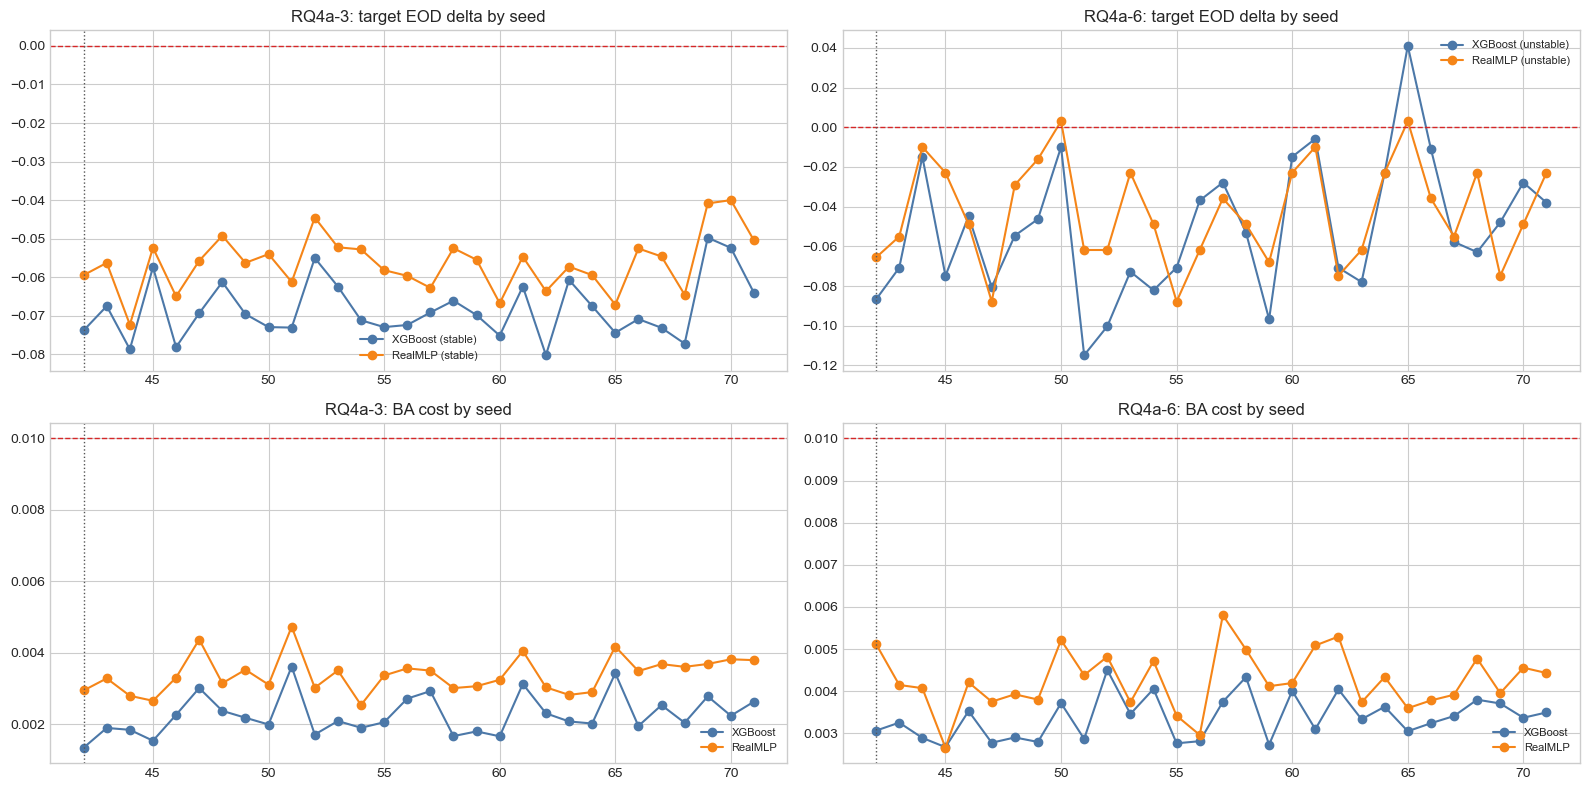

,configuration,model,quantity,min,max,range
0,RQ4a-3,XGBoost,mitigated_target_eod,0.03482,0.06527,0.03045
1,RQ4a-3,XGBoost,delta_target_eod,-0.08019,-0.04974,0.03045
2,RQ4a-3,XGBoost,mitigated_ba,0.77937,0.78164,0.00227
3,RQ4a-3,XGBoost,ba_cost,0.00135,0.00362,0.00227
4,RQ4a-3,RealMLP,mitigated_target_eod,0.02026,0.05254,0.03228
5,RQ4a-3,RealMLP,delta_target_eod,-0.07227,-0.03999,0.03228
6,RQ4a-3,RealMLP,mitigated_ba,0.77806,0.78025,0.00219
7,RQ4a-3,RealMLP,ba_cost,0.00254,0.00473,0.00219
8,RQ4a-6,XGBoost,mitigated_target_eod,0.05233,0.20823,0.15591
9,RQ4a-6,XGBoost,delta_target_eod,-0.11486,0.04105,0.15591


,configuration_id,model,invalid_reason_codes,seeds
0,RQ4a-3,realmlp,none,30
1,RQ4a-3,xgboost,none,30
2,RQ4a-6,realmlp,none,30
3,RQ4a-6,xgboost,none,30


In [10]:
sensitivity = pd.concat([read_csv(configuration, "randomization_sensitivity.csv") for configuration in RUNS], ignore_index=True)
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for col, configuration in enumerate(RUNS):
    for model, color in zip(MODELS, ["#4C78A8", "#F58518"]):
        frame = sensitivity[(sensitivity["configuration_id"] == configuration) & (sensitivity["model"] == model)]
        axes[0, col].plot(frame["seed"], frame["delta_target_eod"], marker="o", color=color, label=f"{MODEL_LABELS[model]} ({summary[configuration]['model_summaries'][model]['stability_status']})")
        axes[1, col].plot(frame["seed"], frame["ba_cost"], marker="o", color=color, label=MODEL_LABELS[model])
    axes[0, col].axhline(0.0, color="#D62728", linestyle="--", linewidth=1)
    axes[1, col].axhline(PRIMARY_BA_BUDGET, color="#D62728", linestyle="--", linewidth=1)
    for row in range(2):
        axes[row, col].axvline(42, color="#555555", linestyle=":", linewidth=1)
        axes[row, col].legend(fontsize=8)
    axes[0, col].set_title(f"{configuration}: target EOD delta by seed")
    axes[1, col].set_title(f"{configuration}: BA cost by seed")
plt.tight_layout()
plt.show()

range_rows = []
for configuration in RUNS:
    for model in MODELS:
        entry = summary[configuration]["model_summaries"][model]
        for key in ["sensitivity_mitigated_target_eod_min_max_range", "sensitivity_delta_target_eod_min_max_range", "sensitivity_mitigated_ba_min_max_range", "sensitivity_ba_cost_min_max_range"]:
            range_rows.append({"configuration": configuration, "model": MODEL_LABELS[model], "quantity": key.replace("sensitivity_", "").replace("_min_max_range", ""), **entry[key]})
display(pd.DataFrame(range_rows).round(5))
display(sensitivity.groupby(["configuration_id", "model"])["invalid_reason_codes"].value_counts().rename("seeds").reset_index())

## Valid and invalid bootstrap replicates

Each quantity keeps all 1,000 replicate rows; an invalid replicate is excluded only from the quantity it invalidates. Every criterion component requires at least 950 valid values. The counts below are read from `bootstrap_summary.csv`.

In [11]:
display(bootstrap.pivot_table(index=["configuration_id", "model_label"], columns="quantity", values=["n_replicates", "n_valid", "valid_gate_status"], aggfunc="first"))

n_replicates                                  n_valid                                  valid_gate_status                                 
quantity                          ba_cost delta_audit_eod delta_target_eod ba_cost delta_audit_eod delta_target_eod           ba_cost delta_audit_eod delta_target_eod
configuration_id model_label                                                                                                                                          
RQ4a-3           RealMLP             1000            1000             1000    1000            1000             1000              pass            pass             pass
                 XGBoost             1000            1000             1000    1000            1000             1000              pass            pass             pass
RQ4a-6           RealMLP             1000            1000             1000    1000            1000             1000              pass            pass             pass
                 XGBoost             1000            1000             1000    1000            1000             1000              pass            pass             pass

## G6 small-group instability

`2 or more minority races` is the smallest G6 group (Validation 106 rows, 49 Approved / 57 Denied; Test 112 rows, 53 / 59 in the stored group metrics below). It clears the 30/30 TPR/FPR gate on the complete partitions, but with few observations its group rates move substantially when decisions change. The table shows its stored values and extremum roles in both configurations.

In [12]:
small = race[race["group"] == "2 or more minority races"][["configuration_id", "model", "partition", "policy", "in_target_roster", "n_rows", "n_actual_approved", "n_actual_denied", "tpr", "fpr", "selection_rate", "tpr_valid", "fpr_valid", "selection_rate_valid", "tpr_extremum_role", "fpr_extremum_role"]]
small = small.assign(model=small["model"].map(MODEL_LABELS))
display(small.round(4))

,configuration_id,model,partition,policy,in_target_roster,n_rows,n_actual_approved,n_actual_denied,tpr,fpr,selection_rate,tpr_valid,fpr_valid,selection_rate_valid,tpr_extremum_role,fpr_extremum_role
4,RQ4a-3,XGBoost,validation,baseline,False,106,49,57,0.8980,0.1930,0.5189,True,True,True,none,none
18,RQ4a-3,XGBoost,validation,mitigated,False,106,49,57,0.8980,0.1930,0.5189,True,True,True,max,none
32,RQ4a-3,XGBoost,test,baseline,False,112,53,59,0.8679,0.1525,0.4911,True,True,True,none,min
46,RQ4a-3,XGBoost,test,mitigated,False,112,53,59,0.8679,0.1525,0.4911,True,True,True,none,min
60,RQ4a-3,RealMLP,validation,baseline,False,106,49,57,0.9388,0.2105,0.5472,True,True,True,none,none
74,RQ4a-3,RealMLP,validation,mitigated,False,106,49,57,0.9388,0.2105,0.5472,True,True,True,max,none
88,RQ4a-3,RealMLP,test,baseline,False,112,53,59,0.9245,0.2203,0.5536,True,True,True,none,none
102,RQ4a-3,RealMLP,test,mitigated,False,112,53,59,0.9245,0.2203,0.5536,True,True,True,max,none
116,RQ4a-6,XGBoost,validation,baseline,True,106,49,57,0.8980,0.1930,0.5189,True,True,True,none,none
130,RQ4a-6,XGBoost,validation,mitigated,True,106,49,57,0.8980,0.2982,0.5755,True,True,True,max,none


## Fairness generalization gap

`fairness_generalization_gap = Test EOD - Validation EOD`, stored per policy in `model_summary.json`. Validation is the complete-Validation development partition that also fitted the policy, so the mitigated gap reflects how well the fitted equalization transfers to Test.

In [13]:
gap_rows = []
for configuration in RUNS:
    for model in MODELS:
        entry = summary[configuration]["model_summaries"][model]
        for eod in ["eod3", "eod6"]:
            gap_rows.append({"configuration": configuration, "model": MODEL_LABELS[model], "eod": eod, **entry[f"fairness_generalization_gap_{eod}"]})
display(pd.DataFrame(gap_rows).round(5))

,configuration,model,eod,baseline,mitigated
0,RQ4a-3,XGBoost,eod3,0.01495,0.03033
1,RQ4a-3,XGBoost,eod6,-0.04693,-0.03220
2,RQ4a-3,RealMLP,eod3,0.01832,0.02001
3,RQ4a-3,RealMLP,eod6,-0.02801,-0.02801
4,RQ4a-6,XGBoost,eod3,0.01495,0.04855
5,RQ4a-6,XGBoost,eod6,-0.04693,0.00861
6,RQ4a-6,RealMLP,eod3,0.01832,0.01529
7,RQ4a-6,RealMLP,eod6,-0.02801,0.08059


## Key values for reconciliation

The values below are copied without transformation from the reporting artifacts, so they can be compared directly with the stored files.

In [14]:
key_values = {}
for configuration in RUNS:
    for model in MODELS:
        entry = summary[configuration]["model_summaries"][model]
        boot = bootstrap[(bootstrap["configuration_id"] == configuration) & (bootstrap["model"] == model)].set_index("quantity")
        test_rows = experiment[(experiment["configuration_id"] == configuration) & (experiment["model"] == model) & (experiment["partition"] == "test")].set_index("policy")
        key_values[f"{configuration}/{model}"] = {
            "status": [entry["execution_status"], entry["stability_status"], entry["primary_criterion"], entry["reason_codes"]],
            "bootstrap": {q: [float(boot.loc[q, "point_estimate"]), float(boot.loc[q, "ci_lower"]), float(boot.loc[q, "ci_upper"]), int(boot.loc[q, "n_valid"])] for q in ["delta_target_eod", "ba_cost", "delta_audit_eod"]},
            "test": {p: {m: float(test_rows.loc[p, m]) for m in ["balanced_accuracy", "eod3", "eod6"]} for p in ["baseline", "mitigated"]},
        }
print(json.dumps(key_values, indent=1))

{
 "RQ4a-3/xgboost": {
  "status": [
   "completed",
   "stable",
   "pass",
   [
    "none"
   ]
  ],
  "bootstrap": {
   "delta_target_eod": [
    -0.07376554459093326,
    -0.10750497088150959,
    -0.024551773456444333,
    1000
   ],
   "ba_cost": [
    0.0013450434099999686,
    0.0001306095947060283,
    0.006294765069871016,
    1000
   ],
   "delta_audit_eod": [
    0.0,
    -0.041776423420499295,
    0.04356131516558413,
    1000
   ]
  },
  "test": {
   "baseline": {
    "balanced_accuracy": 0.7829818365685688,
    "eod3": 0.11500162801337033,
    "eod6": 0.16718551827510666
   },
   "mitigated": {
    "balanced_accuracy": 0.7816367931585688,
    "eod3": 0.041236083422437064,
    "eod6": 0.16718551827510666
   }
  }
 },
 "RQ4a-3/realmlp": {
  "status": [
   "completed",
   "stable",
   "pass",
   [
    "none"
   ]
  ],
  "bootstrap": {
   "delta_target_eod": [
    -0.05943120686207293,
    -0.08391859560686973,
    -0.007912187677731485,
    1000
   ],
   "ba_cost": [
    0.

## Interpretation boundary

- **RQ4a-3 (primary, G3):** read the status table and the paired intervals above for each model. A `pass` means only that the four locked conditions held: point and upper-CI target EOD reduction below zero, and point and upper-CI BA cost within 0.01.
- **RQ4a-6 (required sensitivity, G6):** reported as predeclared. It is not promoted to the primary analysis after seeing results. A `fail` or `unstable` outcome is a study result, not an execution failure; the small `2 or more minority races` cell, whose group rates shift strongly after mitigation, plausibly contributes to the wider intervals; this is an interpretation, not a decomposition computed by the run.
- Models are evaluated separately; they are not pooled, ranked, or selected on fairness results.
- ROC-AUC and Brier are inherited from frozen scores; post-processing changes decisions only and does not improve them.
- A smaller observed EOD does not establish the absence of unfairness. These outputs are exploratory model-behaviour evidence for the documented HMDA approval cohort and cannot establish legal compliance, discrimination, causal effects, creditworthiness, or default risk.